# Nabootsen masterproef

Ik was heel verward met alle mappen en bestand en datatypes die de student heeft gebruikt dus ik ga proberen om alles na te bootsen in mijn eigen directory zodat de directorytree overzichtelijker wordt.

In [1]:
import numpy as np
import pandas as pd
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
import constants
import os
import time
import gc
import torch
import csv
from torchvision import transforms
import torch.nn as nn
import cv2
from random import randint
import matplotlib.pyplot as plt
import matplotlib.patches as patches

c:\Python310\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Er wordt een eigen pythonbestand aangemaakt met een aantal constanten: 
- de breedte en hoogte van de foto's in pixels
- de breedte van de gecropte foto
- de breedte en hoeveel overlap ieder vierkant segment heeft

Om het project te beginnen moet je een map hebben `data` met daaronder 2 submappen: 
- `images_full` de originele foto's van 7951x5303px
- `labels_full_json` de originel labels in json

In [2]:
def split_image(img, size):
    data = []
    y = 0
    while(y < constants.Y_END - size):
        x = 0
        while(x < constants.X_END - size):
            x_end = x+size if x+size < constants.X_END else constants.X_END
            y_end = y+size if y+size < constants.Y_END else constants.Y_END
            data.append(img[y:y_end,x:x_end])
            x += size - constants.OVERLAP
        y += size - constants.OVERLAP
    return data

In [3]:
def get_ground_truth(filename, count, width, x_length):
    gt = np.zeros(count)
    f = open(filename, "r")
    for line in f:
        arr = line.split("\t")
        x_center = float(arr[1])
        y_center = float(arr[2])
        index = int(x_center//width + (x_length//width) * (y_center//width))
        try:
            gt[index] = 1
        except:
            continue
    return gt


In [4]:
def downsample(img):
    downscaled = skimage.transform.resize(img, (64,64), anti_aliasing=True)
    return downscaled

def downsample_opencv(img):
    blur = cv2.GaussianBlur(img,(23,23),0)
    downscaled = cv2.resize(blur, (64,64), cv2.INTER_AREA)
    return downscaled

In [5]:
class Filter(nn.Module):
    def __init__(self):
        super(Filter, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(2048, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

In [6]:
#functie die inference doet voor een bepaald model en bepaalde data (geen datafolder) en enkel nuttige data teruggeeft
# data is an aarray of images
def inference(modelname, data, threshold):
    if len(data) == 0:
        return [], 0
    data_ = [downsample(np.array(i)) for i in data]
    start = time.time()
    model = Filter()
    model.cuda()
    model.load_state_dict(torch.load(f"./trained_models/{modelname}.pth"))
    model.eval()
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    # device = torch.device("cpu")
    transform = transforms.Compose([transforms.ToTensor()])
    input = torch.cat([transform(i).float().unsqueeze(0).to(device) for i in data_], 0)
    output = model(input)
    output = output.to(device).data.cpu().numpy()
    filtered_data = []
    for i in range(len(input)):
        if output[i] > threshold:
            filtered_data.append(data[i])
    t = time.time() - start
    return filtered_data, t

In [7]:
#functie die in vier knipt 
def cut_in_parts(data):
    new_data = []
    for im in data:
        M = im.shape[0]//2
        N = im.shape[1]//2
        tiles = [im[x:x+M,y:y+N] for x in range(0,im.shape[0],M) for y in range(0,im.shape[1],N)]
        for tile in tiles:
            new_data.append(tile)
    return new_data

In [8]:
#functie die alles bij elkaar doet: data -> model1 -> filter -> model2 -> filter -> model3 -> filter -> model4; geeft patches terug die positief zijn
def predict_data(data, thresholds):
    torch.cuda.empty_cache()
    t = 0 # time it takes to process image
    all_data = []
    for i in range(1,5):
        filtered_data, t_ = inference(f"model{i}", data, thresholds[i-1])
        all_data.append(filtered_data)
        t += t_
        if(i == 4 ): break
        start = time.time()
        data = cut_in_parts(filtered_data)
        t += time.time() - start
    return filtered_data, t, all_data

In [9]:
def convert_result_to_indexed_array(data, start_data):
    array = np.zeros(len(start_data))
    for i in range(len(start_data)):
        for j in range(len(data)):
            if np.array_equal(start_data[i], data[j]):
                array[i] = 1
    return array

In [10]:
def calculate_stats(gt, predicted):
    tp = tn = fp = fn = 0
    for i in range(len(gt)):
        if gt[i] == 0 and predicted[i] == 0:
            tn += 1
        elif gt[i] == 0 and predicted[i] == 1:
            fp += 1
        elif gt[i] == 1 and predicted[i] == 0:
            fn += 1
        elif gt[i] == 1 and predicted[i] == 1:
            tp += 1
    return tp, tn, fp, fn

In [11]:
def calculate_metrics(tp, tn, fp, fn):
    a = (tp + tn) / (tp + tn + fp + fn)
    if tp + fp > 0:
        p = tp / (tp + fp)
    else:
        p = 0
    r = tp / (tp + fn)
    return a, p, r

In [12]:
#Evalueer perfomantie en snelheid
def evaluate_metrics(imagepath, labelpath):
    teller = 1
    with open('results.csv', mode='w', newline='') as file:
        writer = csv.writer(file, delimiter=',', quotechar='"', quoting=csv.QUOTE_MINIMAL)
        writer.writerow(["p_TP","p_TN","p_FP","p_FN","p_Accuracy","p_Precision","p_Recall","p_Time"])
        
        path = os.path.join(os.getcwd(), imagepath)
        aantal = len(os.listdir(path))
        for filename in os.listdir(path):
            print(f"{teller}/{aantal}")
            filename = filename.split(".")[0]
            img = skimage.io.imread(f"{imagepath}/{filename}.JPG")
            data_512 = split_image(img, 512)
            data_64 = split_image(img, 64)

            gt = get_ground_truth(f"{labelpath}/{filename}.txt", 10168, 64, 7952)
            gc.collect()
            torch.cuda.empty_cache()

            result_pipeline, pt, _ = predict_data(data_512, [0.5, 0.5, 0.5, 0.5])
            pipeline = convert_result_to_indexed_array(result_pipeline, data_64)
            ptp, ptn, pfp, pfn = calculate_stats(gt,pipeline)
            pa, pp, pr = calculate_metrics(ptp, ptn, pfp, pfn)
            print("------------------------------------------")
            print("PIPELINE")
            print(f"tp: {ptp}\ttn: {ptn}\tfp: {pfp}\tfn: {pfn}")
            print("accuracy: "+str(pa))
            print("precision: "+str(pp))
            print("recall: "+str(pr))

            teller += 1

            writer.writerow([ptp, ptn, pfp, pfn, pa, pp, pr, pt])



In [14]:
import json

path = "./data/labels_full_json/"
new_path = "./data/labels_full_txt/"

aantal = len(os.listdir(path))
for filename in os.listdir(path):
    filename = filename.split(".")[0]
    labels = open(f"{path}/{filename}.json")
    data = json.load(labels)
    if not os.path.isdir(new_path):
        os.makedirs(new_path)
    labels_converted = open(f"{new_path}/{filename}.txt", "a")
    for i in data['shapes']:
                    width = i['points'][1][0] - i['points'][0][0]
                    height = i['points'][1][1] - i['points'][0][1]
                    x_center = i['points'][0][0] + width/2
                    y_center = i['points'][0][1] + height/2
                    labels_converted.write(f"0\t{x_center}\t\
                        {y_center}\t\
                        {width}\t\
                        {height}\n")
    labels_converted.close()
    labels.close()

In [13]:
evaluate_metrics("./data/images_test/", "./data/labels_test/")
gc.collect()
torch.cuda.empty_cache()

1/3
------------------------------------------
PIPELINE
tp: 5	tn: 10156	fp: 2	fn: 5
accuracy: 0.9993115656963021
precision: 0.7142857142857143
recall: 0.5
2/3
------------------------------------------
PIPELINE
tp: 5	tn: 10158	fp: 0	fn: 5
accuracy: 0.9995082612116444
precision: 1.0
recall: 0.5
3/3
------------------------------------------
PIPELINE
tp: 6	tn: 10154	fp: 2	fn: 6
accuracy: 0.999213217938631
precision: 0.75
recall: 0.5


In [14]:
#Visualiseer de werking van het model, inclusief een visualisatie van de ground truth
def visualize_inference(filepath):
    #fotoplot met ground truth voor classificatie
    name = filepath.split("/")[-1].split(".")[0]
    imagename = f"./data/images_full/{name}.JPG"
    labelsname = f"./data/labels_full_txt/{name}.txt"
    image = skimage.io.imread(imagename)
    fig, ax = plt.subplots()
    ax.imshow(image)
    gt = get_ground_truth(labelsname, 10168, 64, 7952)
    size = 64
    x = 7952
    for i in range(len(gt)):
        if gt[i] == 1:
            rect = patches.Rectangle((i%(x//size)*size, ((i*size)//x)*size), size, size, edgecolor = 'darkred', facecolor= 'darkred', alpha=0.5)
            ax.add_patch(rect)
    plt.axis('off')       
    plt.savefig(f"./data/{name}_GT.png")

    #fotoplot waarop de keuze van het model wordt geillustreerd
    image = skimage.io.imread(imagename)
    data_512 = split_image(image, 512)
    data_64 = split_image(image, 64)
    predicted, _, filtered_data_arr = predict_data(data_512, [0.5, 0.5, 0.5, 0.5])
    pipeline = convert_result_to_indexed_array(predicted, data_64)

    print(calculate_metrics(*calculate_stats(gt, pipeline)))

    fig, ax = plt.subplots()
    ax.imshow(image)
    size = 512
    x = 7952
    y = 5304

    #voor 1 laag 
    colors = ['aqua', 'yellow', 'orange', 'darkred']

    #split the data in differetn sizes to represent de different step it takes
    data_split = [data_512, split_image(image, 256), split_image(image, 128), data_64]

    for j in range(4):
        arr_len = len(filtered_data_arr[j])
        for i in range(len(data_split[j])):
            for k in range(arr_len):
                if np.array_equal(data_split[j][i],filtered_data_arr[j][k]):
                    rect = patches.Rectangle((i%(x//size)*size, ((i*size)//x)*size), size, size, edgecolor = colors[j], facecolor= colors[j], alpha=(j+1)/4)
                    ax.add_patch(rect)
                    break
        size /= 2
    plt.axis('off')  
    plt.savefig(f"./data/{name}_pipe.png")

(0.999213217938631, 0.75, 0.5)


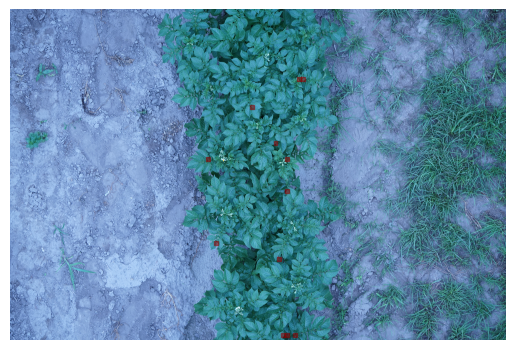

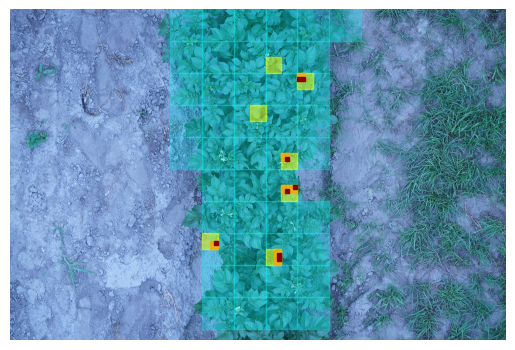

In [15]:
visualize_inference("./data/images_full/DSC00176.JPG")

Index(['p_TP', 'p_TN', 'p_FP', 'p_FN', 'p_Accuracy', 'p_Precision', 'p_Recall',
       'p_Time'],
      dtype='object')


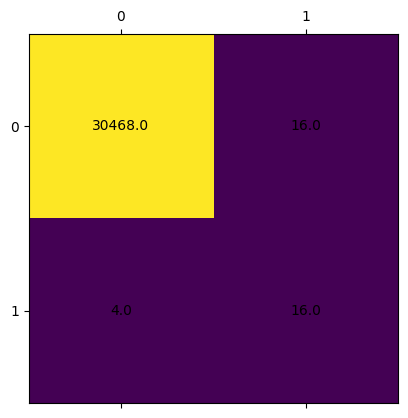

Accuracy: 0.9993443482821925
Precision: 0.8214285714285715
Recall: 0.5
F1 score: 0.6216216216216216


In [25]:
results = pd.read_csv('results.csv')
print(results.columns)
# plt.scatter(results.index, results['p_TP'], label="TP")
# plt.axhline(y=results["p_TP"].mean(), color="blue")

# plt.scatter(results.index, results['p_FN'], label="FN")
# plt.axhline(y=results["p_FN"].mean(), color="orange")
# plt.ylabel("Number of beetels per image")
# plt.legend()
# plt.show()

# fig, axes = plt.subplots(1, 2, figsize = (10,10))
# axes[0].boxplot(results["p_TP"])
# axes[0].set_title("TP")
# axes[0].set_ylim(0,60)
# axes[1].boxplot(results["p_FN"])
# axes[1].set_title("FN")
# axes[1].set_ylim(0,60)
# plt.tight_layout()
# plt.show()

fig, ax = plt.subplots()
ax.matshow([[results["p_TN"].sum(), results["p_FN"].sum()],[results["p_FP"].sum(), results["p_TP"].sum()]])

for (i, j), z in np.ndenumerate([[results["p_TN"].sum(), results["p_FN"].sum()],[results["p_FP"].sum(), results["p_TP"].sum()]]):
    ax.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')

plt.show()

avg_accuracy = results["p_Accuracy"].mean()
print(f"Accuracy: {avg_accuracy}")
avg_precision = results["p_Precision"].mean()
print(f"Precision: {avg_precision}")
avg_recall = results["p_Recall"].mean()
print(f"Recall: {avg_recall}")
f1 = 2* (avg_precision * avg_recall) / (avg_precision + avg_recall)
print(f"F1 score: {f1}")
